# J2 : MetroPT-3, traitements A et B

**Objectif.** Expliquer, étape par étape, comment la référence Python calcule des indicateurs par fenêtres de 5 minutes
(traitement A) puis des variables temporelles pour le datamining (traitement B), et montrer les résultats.

**Ce que ce notebook est, et n'est pas.**
- Il **appelle** les fonctions de `src/` : le calcul n'est pas recopié ici. Les scripts `src/*.py` et les tests restent la référence.
- Il sépare toujours les **exemples pédagogiques** (chiffres fictifs ou issus du guide) des **résultats mesurés** sur tes fichiers.
- Si les vrais fichiers sont absents, il s'exécute sur des **données synthétiques**, annoncées clairement dans chaque figure.
  Pour obtenir les vrais résultats, lance d'abord `python -m src.metropt3_reference ...` (voir le README), puis relance ce notebook.

In [1]:
from pathlib import Path
import json, sys, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Racine du projet (ce notebook est dans notebooks/) : on importe le code de src/, on ne le recopie pas.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
TMP = Path(tempfile.mkdtemp(prefix="bigdata_nb_"))   # fichiers temporaires : data/ n'est jamais modifié

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (9, 3.6)})
print("Racine du projet :", ROOT)

from src.common import compare_results, finalize_moments, merge_moments
from src.metropt3_reference import ANALOG_VARS, BINARY_VARS, TS_COL, chunk_moments, compute_features
from src.datamining_features import metropt3_datamining

Racine du projet : /home/claude/BigData_Project


## 1. Les formules

Pour chaque fenêtre de 5 minutes, alignée sur l'horloge (`floor(timestamp, 5 min)`, borne basse incluse), on calcule pour chaque variable :

- effectif $n$ ; moyenne $\bar{x}=\dfrac{\sum x_i}{n}$ ; maximum ;
- écart-type de **population** $\sigma=\sqrt{\dfrac{\sum (x_i-\bar{x})^2}{n}}$ (diviseur $n$, pas $n-1$, comme dans NumPy, pandas avec `ddof=0` et Spark `stddev_pop`).

**Calcul par blocs.** Le fichier est lu par morceaux, et une même fenêtre peut être coupée entre deux morceaux. Chaque bloc fournit
$(n,\ \bar{x},\ M_2,\ \max)$ avec $M_2=\sum (x_i-\bar{x})^2$, et deux blocs A et B sont fusionnés par la formule stable de Chan :

$$n=n_A+n_B,\qquad \bar{x}=\bar{x}_A+\delta\,\frac{n_B}{n},\qquad M_2=M_{2A}+M_{2B}+\delta^2\,\frac{n_A n_B}{n},\qquad \delta=\bar{x}_B-\bar{x}_A$$

On ne fait **jamais** la moyenne des moyennes de blocs : cela donne un résultat faux dès que les blocs n'ont pas la même taille.

## 2. Exemple pédagogique du guide (§9) : pourquoi pas la moyenne des moyennes ?

Une même fenêtre est coupée en deux blocs : $[60, 62]$ et $[64, 66, 68]$. *(Ces chiffres viennent du guide, ce ne sont pas des mesures MetroPT-3.)*

In [2]:
ex = pd.DataFrame({
    TS_COL: pd.to_datetime([f"2020-02-01 10:00:{s:02d}" for s in (0, 10, 20, 30, 40)]),
    "x": [60.0, 62.0, 64.0, 66.0, 68.0],
})
_, bloc1 = chunk_moments(ex.iloc[:2], ["x"], "5min")      # fonction de src/metropt3_reference.py
_, bloc2 = chunk_moments(ex.iloc[2:], ["x"], "5min")
fusion = finalize_moments(merge_moments(bloc1["x"], bloc2["x"])).iloc[0]
moyenne_des_moyennes = (ex.x[:2].mean() + ex.x[2:].mean()) / 2

print(f"Fusion des blocs (n, moyenne, M2)   : n = {int(fusion['n'])}, moyenne = {fusion['mean']}  (320 / 5)")
print(f"Moyenne des moyennes de blocs       : {moyenne_des_moyennes}   <- FAUX")
print(f"Écart-type de population : {fusion['std_pop']:.4f}  (contrôle NumPy : {np.std(ex.x, ddof=0):.4f})")

Fusion des blocs (n, moyenne, M2)   : n = 5, moyenne = 64.0  (320 / 5)
Moyenne des moyennes de blocs       : 63.5   <- FAUX
Écart-type de population : 2.8284  (contrôle NumPy : 2.8284)


## 3. Les données utilisées dans ce notebook

Ordre de priorité : résultats déjà calculés par le script → calcul à partir du CSV réel → données synthétiques (secours).

In [3]:
REAL_CSV = ROOT / "data" / "metropt3" / "MetroPT3(AirCompressor).csv"
FEATURES_CSV = ROOT / "results" / "metropt3" / "metropt3_features.csv"
REPORT_JSON = ROOT / "results" / "metropt3" / "metropt3_quality_report.json"


def make_synthetic_csv(path, hours=8):
    """Données SYNTHÉTIQUES : pas de ~10 s avec gigue, un trou de 30 min, un signal périodique."""
    rng = np.random.default_rng(7)
    steps = rng.integers(8, 14, int(hours * 360))
    ts = pd.Timestamp("2020-02-01 00:00:00") + pd.to_timedelta(np.cumsum(steps), unit="s")
    ts = ts[(ts < "2020-02-01 04:00:00") | (ts >= "2020-02-01 04:30:00")]
    t_h = (ts - ts[0]).total_seconds() / 3600
    df = pd.DataFrame({"timestamp": ts.strftime("%Y-%m-%d %H:%M:%S")})
    df["TP2"] = np.where((np.sin(2 * np.pi * t_h / 0.5) > 0), 8.5, -0.012) + rng.normal(0, 0.05, len(ts))
    df["TP3"] = 9.3 + rng.normal(0, 0.05, len(ts))
    df["H1"] = 9.2 + rng.normal(0, 0.05, len(ts))
    df["DV_pressure"] = -0.02 + rng.normal(0, 0.01, len(ts))
    df["Reservoirs"] = 9.3 + rng.normal(0, 0.05, len(ts))
    df["Oil_temperature"] = 62 + 8 * np.sin(2 * np.pi * t_h / 2.0) + rng.normal(0, 0.6, len(ts))
    df["Motor_current"] = np.where(df["TP2"] > 1, 4.0 + rng.normal(0, 0.1, len(ts)), 0.04)
    for c in BINARY_VARS:
        df[c] = rng.integers(0, 2, len(ts))
    df.to_csv(path, index=False)
    return path


report = {}
if FEATURES_CSV.exists():
    SOURCE = "réel (résultats déjà calculés par le script)"
    feats = pd.read_csv(FEATURES_CSV, parse_dates=["window_start"])
    if REPORT_JSON.exists():
        report = json.loads(REPORT_JSON.read_text(encoding="utf-8"))
    SMALL_CSV = None
elif REAL_CSV.exists():
    SOURCE = "réel (calculé ici à partir du CSV)"
    feats = compute_features(REAL_CSV, ANALOG_VARS, report=report)
    feats["window_start"] = pd.to_datetime(feats["window_start"])
    SMALL_CSV = None
else:
    SOURCE = "SYNTHÉTIQUE"
    synth = make_synthetic_csv(TMP / "metropt3_synthetique.csv")
    feats = compute_features(synth, ANALOG_VARS, chunksize=2_000, report=report)
    feats["window_start"] = pd.to_datetime(feats["window_start"])
    SMALL_CSV = synth

SYNTHETIC = SOURCE == "SYNTHÉTIQUE"
TAG = "  [DONNÉES SYNTHÉTIQUES]" if SYNTHETIC else ""
if SMALL_CSV is None and REAL_CSV.exists():           # extrait réel pour la comparaison de blocs plus bas
    SMALL_CSV = TMP / "extrait.csv"
    pd.read_csv(REAL_CSV, nrows=30_000).to_csv(SMALL_CSV, index=False)

print("Source des données :", SOURCE)
if SYNTHETIC:
    print("ATTENTION : aucune donnée réelle trouvée. Tout ce qui suit est un exemple sur données synthétiques.")
print(f"{len(feats)} fenêtres de 5 minutes ; colonnes : {list(feats.columns[:5])} ...")
feats.head()

Source des données : SYNTHÉTIQUE
ATTENTION : aucune donnée réelle trouvée. Tout ce qui suit est un exemple sur données synthétiques.
96 fenêtres de 5 minutes ; colonnes : ['window_start', 'n', 'TP2_mean', 'TP2_max', 'TP2_std_pop'] ...


,window_start,n,TP2_mean,TP2_max,TP2_std_pop,TP3_mean,TP3_max,TP3_std_pop,H1_mean,H1_max,...,DV_pressure_std_pop,Reservoirs_mean,Reservoirs_max,Reservoirs_std_pop,Oil_temperature_mean,Oil_temperature_max,Oil_temperature_std_pop,Motor_current_mean,Motor_current_max,Motor_current_std_pop
0,2020-02-01 00:00:00,28,8.189317,8.618122,1.586602,9.314971,9.391487,0.047311,9.199050,9.274131,...,0.009821,9.295737,9.412766,0.056167,63.102451,65.073339,0.837953,3.850515,4.152179,0.739489
1,2020-02-01 00:05:00,27,8.500413,8.632540,0.060032,9.289902,9.405633,0.054887,9.199254,9.312825,...,0.008642,9.297881,9.372519,0.047245,64.892860,66.285597,0.809888,4.006495,4.168155,0.101147
2,2020-02-01 00:10:00,29,8.497456,8.632765,0.050629,9.308096,9.420052,0.048511,9.190713,9.268243,...,0.011309,9.301495,9.403383,0.040913,66.612218,68.130996,0.853495,4.013610,4.209722,0.116364
3,2020-02-01 00:15:00,29,0.299790,8.478643,1.546542,9.283874,9.367938,0.055573,9.202549,9.322933,...,0.011373,9.291823,9.401799,0.055514,68.394841,69.662343,0.641608,0.180090,4.102604,0.741285
4,2020-02-01 00:20:00,28,-0.006726,0.137412,0.059084,9.278472,9.390567,0.050857,9.196317,9.331509,...,0.006736,9.305812,9.389108,0.048919,69.347527,70.322516,0.579891,0.040000,0.040000,0.000000


## 4. Traitement A : le tableau par fenêtres

Une ligne par fenêtre **non vide**. Une période sans mesure ne produit **aucune ligne** : rien n'est inventé, rien n'est interpolé.
`n` est le nombre de lignes du fichier tombées dans la fenêtre (environ 30 à la cadence de 10 s).

In [4]:
cols = ["window_start", "n", "Oil_temperature_mean", "Oil_temperature_max", "Oil_temperature_std_pop"]
display(feats[cols].head(8))

grille = pd.date_range(feats.window_start.min(), feats.window_start.max(), freq="5min")
manquantes = grille.difference(feats.window_start)
print(f"Fenêtres produites : {len(feats)} sur {len(grille)} possibles ; fenêtres absentes (périodes sans mesure) : {len(manquantes)}")

,window_start,n,Oil_temperature_mean,Oil_temperature_max,Oil_temperature_std_pop
0,2020-02-01 00:00:00,28,63.102451,65.073339,0.837953
1,2020-02-01 00:05:00,27,64.892860,66.285597,0.809888
2,2020-02-01 00:10:00,29,66.612218,68.130996,0.853495
3,2020-02-01 00:15:00,29,68.394841,69.662343,0.641608
4,2020-02-01 00:20:00,28,69.347527,70.322516,0.579891
5,2020-02-01 00:25:00,28,69.987540,70.990706,0.435673
6,2020-02-01 00:30:00,29,69.999649,71.025440,0.545960
7,2020-02-01 00:35:00,28,69.529211,70.943064,0.619215


Fenêtres produites : 96 sur 102 possibles ; fenêtres absentes (périodes sans mesure) : 6


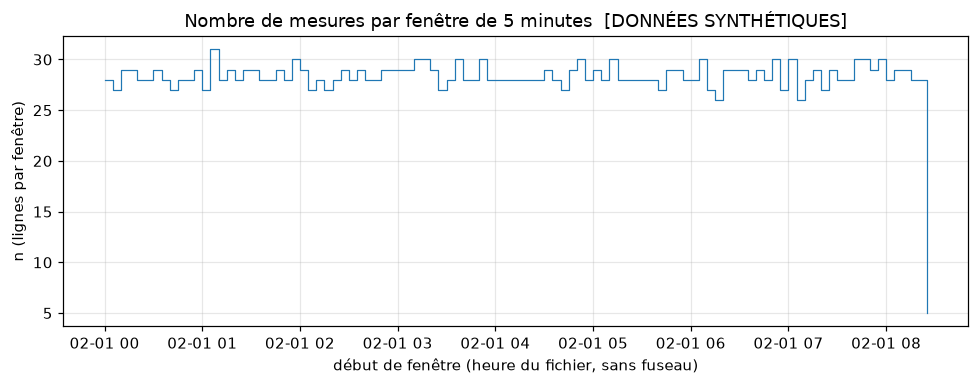

Une fenêtre pleine contient environ 30 lignes ; un creux signale un début ou une fin de trou.


In [5]:
# Effectif par fenêtre : les fenêtres incomplètes (avant ou après un trou, ou aux extrémités) ressortent.
fig, ax = plt.subplots()
ax.step(feats.window_start, feats.n, where="post", lw=0.8, color="#1f77b4")
ax.set_title("Nombre de mesures par fenêtre de 5 minutes" + TAG)
ax.set_xlabel("début de fenêtre (heure du fichier, sans fuseau)")
ax.set_ylabel("n (lignes par fenêtre)")
plt.tight_layout(); plt.show()
print("Une fenêtre pleine contient environ 30 lignes ; un creux signale un début ou une fin de trou.")

### Moyenne, maximum et écart-type sur une variable

Les fenêtres absentes sont replacées sur une grille régulière **uniquement pour l'affichage** : la courbe s'interrompt au lieu de relier
deux points séparés par un trou.

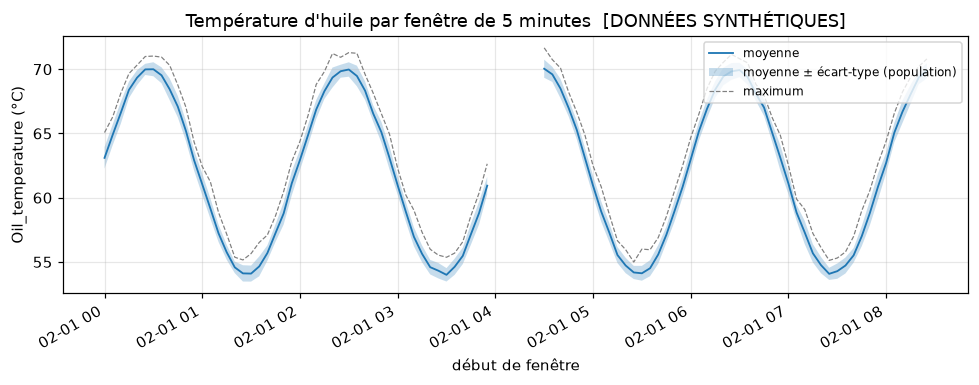

In [6]:
g = feats.set_index("window_start").reindex(grille)
if SYNTHETIC:
    vue = g
else:                                                 # zoom autour du premier rapport de panne (J1 : 2020-04-18)
    vue = g.loc["2020-04-16":"2020-04-20"]
fig, ax = plt.subplots()
ax.plot(vue.index, vue.Oil_temperature_mean, lw=1.2, label="moyenne")
ax.fill_between(vue.index, vue.Oil_temperature_mean - vue.Oil_temperature_std_pop,
                vue.Oil_temperature_mean + vue.Oil_temperature_std_pop, alpha=0.25, label="moyenne ± écart-type (population)")
ax.plot(vue.index, vue.Oil_temperature_max, lw=0.8, ls="--", color="gray", label="maximum")
if not SYNTHETIC:
    ax.axvspan(pd.Timestamp("2020-04-18 00:00"), pd.Timestamp("2020-04-18 23:59"), color="red", alpha=0.08, label="rapport de panne (J1)")
ax.set_title("Température d'huile par fenêtre de 5 minutes" + TAG)
ax.set_xlabel("début de fenêtre"); ax.set_ylabel("Oil_temperature (°C)")
ax.legend(loc="upper right", fontsize=8); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 5. Le résultat ne dépend pas de la taille des blocs

Même fichier lu par blocs de 700 lignes puis en un seul bloc : mêmes clés, même nombre de lignes, valeurs dans la tolérance
$|v-r|\le 10^{-9}+10^{-9}|r|$ (fixée en J1 avant toute comparaison).

In [7]:
if SMALL_CSV is None:
    print("Aucun CSV disponible pour cette comparaison.")
else:
    a = compute_features(SMALL_CSV, ANALOG_VARS, chunksize=700)
    b = compute_features(SMALL_CSV, ANALOG_VARS, chunksize=10**6)
    for d in (a, b):
        d["window_start"] = pd.to_datetime(d["window_start"])
    compare_results(a, b, ["window_start"])             # lève une AssertionError au moindre écart
    print(f"OK : {len(a)} fenêtres identiques entre blocs de 700 lignes et lecture en un seul bloc.")

OK : 96 fenêtres identiques entre blocs de 700 lignes et lecture en un seul bloc.


## 6. Rapport de qualité

Le script consigne ce qu'il rencontre, sans rien supprimer silencieusement. Pour les vrais fichiers, la colonne « attendu » reprend la fiche d'audit J1.

In [8]:
if not report:
    print("Pas de rapport : lance python -m src.metropt3_reference pour en produire un.")
else:
    obs = {
        "rows_read": report["rows_read"],
        "rows_bad_timestamp": report["rows_bad_timestamp"],
        "adjacent_duplicate_timestamps": report["adjacent_duplicate_timestamps"],
        "non_monotonic_steps": report["non_monotonic_steps"],
        "valeurs invalides ou manquantes (total)": sum(report["invalid_or_missing"].values()),
        "excluded_total": report["excluded_total"],
        "first_timestamp": report["first_timestamp"],
        "last_timestamp": report["last_timestamp"],
        "timestamp_format": report["timestamp_format"],
    }
    j1 = {"rows_read": 1516948, "rows_bad_timestamp": 0, "adjacent_duplicate_timestamps": 0, "non_monotonic_steps": 0,
          "valeurs invalides ou manquantes (total)": 0, "excluded_total": 0,
          "first_timestamp": "2020-02-01 00:00:00", "last_timestamp": "2020-09-01 03:59:50"}
    tab = pd.DataFrame({"observé": obs})
    if SYNTHETIC:
        tab["attendu (J1)"] = "n/a (synthétique)"
    else:
        tab["attendu (J1)"] = pd.Series(j1)
        tab["conforme"] = [("oui" if k in j1 and str(j1[k]) == str(v) else ("-" if k not in j1 else "NON")) for k, v in obs.items()]
    display(tab)

,observé,attendu (J1)
rows_read,2709,n/a (synthétique)
rows_bad_timestamp,0,n/a (synthétique)
adjacent_duplicate_timestamps,0,n/a (synthétique)
non_monotonic_steps,0,n/a (synthétique)
valeurs invalides ou manquantes (total),0,n/a (synthétique)
excluded_total,0,n/a (synthétique)
first_timestamp,2020-02-01 00:00:13,n/a (synthétique)
last_timestamp,2020-02-01 08:25:50,n/a (synthétique)
timestamp_format,%Y-%m-%d %H:%M:%S,n/a (synthétique)


## 7. Traitement B : variables temporelles pour le datamining

À partir des fenêtres, pour un indicateur $x$ (ici la moyenne de la température d'huile) :

- **variation** : $x_t - x_{t-1}$ (fenêtre immédiatement précédente) ;
- **moyenne historique** : moyenne des fenêtres des $H$ minutes précédentes, pondérée par $n$, **strictement antérieures** (aucune fuite du futur) ;
- **écart à l'historique** : $x_t - \text{hist}_t$.

**Les fenêtres absentes restent identifiables** : la série est replacée sur la grille complète, la ligne manquante porte `is_missing_window = True`
et n'est ni remplie ni interpolée. L'historique se mesure en **durée**, pas en nombre de lignes.

> Avec des fenêtres de 5 min, « les 5 minutes précédentes » ne contiennent qu'**une** fenêtre : la moyenne historique vaut alors la valeur précédente.
> Pour que l'indicateur apporte quelque chose sur MetroPT-3, on prend ici un historique de 30 minutes (6 fenêtres).

In [9]:
dm = metropt3_datamining(feats, history_minutes=30, variables=["Oil_temperature"])
cols = ["window_start", "is_missing_window", "n", "Oil_temperature_mean", "Oil_temperature_mean_variation",
        "Oil_temperature_mean_hist_mean", "Oil_temperature_mean_vs_hist", "hist_n_windows", "hist_complete"]
display(dm[cols].head(8))

premiere = dm.index[dm.is_missing_window][:1]
if len(premiere):
    i = int(premiere[0])
    print("Autour de la première fenêtre absente (ligne conservée, variation vide sur elle et sur la suivante) :")
    display(dm[cols].iloc[max(i - 2, 0): i + 3])

,window_start,is_missing_window,n,Oil_temperature_mean,Oil_temperature_mean_variation,Oil_temperature_mean_hist_mean,Oil_temperature_mean_vs_hist,hist_n_windows,hist_complete
0,2020-02-01 00:00:00,False,28,63.102451,NaN,NaN,NaN,0,False
1,2020-02-01 00:05:00,False,27,64.892860,1.790409,63.102451,1.790409,1,False
2,2020-02-01 00:10:00,False,29,66.612218,1.719358,63.981379,2.630839,2,False
3,2020-02-01 00:15:00,False,29,68.394841,1.782624,64.889645,3.505197,3,False
4,2020-02-01 00:20:00,False,28,69.347527,0.952686,65.789208,3.558319,4,False
5,2020-02-01 00:25:00,False,28,69.987540,0.640013,66.495825,3.491715,5,False
6,2020-02-01 00:30:00,False,29,69.999649,0.012108,67.074334,2.925315,6,True
7,2020-02-01 00:35:00,False,28,69.529211,-0.470437,68.227551,1.301660,6,True


Autour de la première fenêtre absente (ligne conservée, variation vide sur elle et sur la suivante) :


,window_start,is_missing_window,n,Oil_temperature_mean,Oil_temperature_mean_variation,Oil_temperature_mean_hist_mean,Oil_temperature_mean_vs_hist,hist_n_windows,hist_complete
46,2020-02-01 03:50:00,False,30,58.807952,1.648573,55.026052,3.781900,6,True
47,2020-02-01 03:55:00,False,28,60.939566,2.131615,55.762752,5.176815,6,True
48,2020-02-01 04:00:00,True,0,NaN,NaN,56.831747,NaN,6,True
49,2020-02-01 04:05:00,True,0,NaN,NaN,57.382419,NaN,5,False
50,2020-02-01 04:10:00,True,0,NaN,NaN,58.107938,NaN,4,False


### Cinq lignes précédentes ≠ cinq minutes précédentes

Exemple pédagogique (valeurs fictives) : trois fenêtres de 5 min, puis un trou de deux fenêtres, puis deux fenêtres.
Un calcul « sur les 3 lignes précédentes » traverse le trou et mélange des périodes éloignées ; le calcul en durée ne retient que ce qui existe réellement.

In [10]:
mini = pd.DataFrame({
    "window_start": pd.Timestamp("2020-02-01 10:00") + pd.to_timedelta([0, 5, 10, 25, 30], unit="min"),
    "n": 30, "A_mean": [10.0, 20.0, 30.0, 100.0, 110.0],
})
par_lignes = mini["A_mean"].shift(1).rolling(3, min_periods=1).mean()          # FAUX avec des trous
en_duree = metropt3_datamining(mini, history_minutes=15)                       # 3 fenêtres de 5 min, grille complète
comp = pd.DataFrame({
    "window_start": mini.window_start,
    "valeur": mini.A_mean,
    "historique par LIGNES (faux)": par_lignes.round(2),
})
comp = comp.merge(en_duree[["window_start", "A_mean_hist_mean", "hist_n_windows"]], on="window_start")
comp = comp.rename(columns={"A_mean_hist_mean": "historique en DURÉE (15 min)", "hist_n_windows": "fenêtres réellement présentes"})
display(comp)
print("À 10:25, la version par lignes moyenne 10:00-10:10 (il y a plus de 15 min) ; la version en durée ne voit que ce qui existe dans 10:10-10:25.")

,window_start,valeur,historique par LIGNES (faux),historique en DURÉE (15 min),fenêtres réellement présentes
0,2020-02-01 10:00:00,10.0,NaN,NaN,0
1,2020-02-01 10:05:00,20.0,10.0,10.0,1
2,2020-02-01 10:10:00,30.0,15.0,15.0,2
3,2020-02-01 10:25:00,100.0,20.0,30.0,1
4,2020-02-01 10:30:00,110.0,50.0,100.0,1


À 10:25, la version par lignes moyenne 10:00-10:10 (il y a plus de 15 min) ; la version en durée ne voit que ce qui existe dans 10:10-10:25.


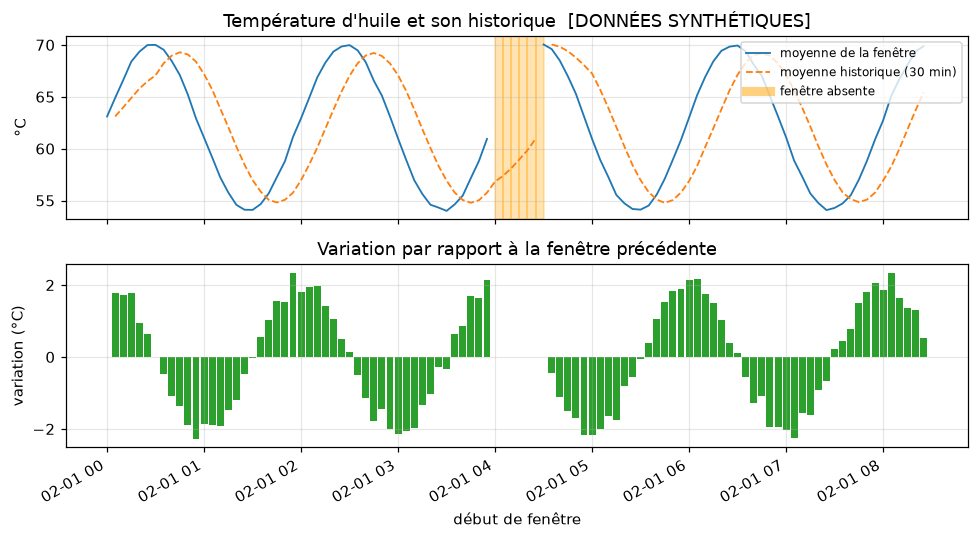

In [11]:
d = dm.set_index("window_start")
vue = d if SYNTHETIC else d.loc["2020-04-16":"2020-04-20"]
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 5))
ax1.plot(vue.index, vue.Oil_temperature_mean, lw=1.2, label="moyenne de la fenêtre")
ax1.plot(vue.index, vue.Oil_temperature_mean_hist_mean, lw=1.2, ls="--", label="moyenne historique (30 min)")
manq = vue[vue.is_missing_window]
for t in manq.index:
    ax1.axvspan(t, t + pd.Timedelta("5min"), color="orange", alpha=0.3)
ax1.plot([], [], color="orange", alpha=0.5, lw=6, label="fenêtre absente")
ax1.set_ylabel("°C"); ax1.set_title("Température d'huile et son historique" + TAG); ax1.legend(fontsize=8, loc="upper right")
ax2.bar(vue.index, vue.Oil_temperature_mean_variation, width=0.003, color="#2ca02c")
ax2.set_ylabel("variation (°C)"); ax2.set_xlabel("début de fenêtre"); ax2.set_title("Variation par rapport à la fenêtre précédente")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 8. À retenir et limites

- Le notebook **ne remplace pas** `src/metropt3_reference.py` ni `src/datamining_features.py` : il les appelle et les explique.
- Moyenne = **moyenne des observations**, non pondérée par le temps (le pas est irrégulier : environ 10 s avec de la gigue, des trous allant jusqu'à environ 48 h).
- Les horodatages n'ont pas de fuseau : ils sont utilisés tels quels.
- Un exemple de datamining sur MetroPT-3 au sens du guide (§18, détection d'anomalies sur ces indicateurs) reste à faire dans les étapes suivantes.
- Les exemples numériques de ce notebook illustrent les formules ; les résultats mesurés sont ceux des sections 3, 4 et 6 lorsque la source est « réel ».